# Linear Regression

Let's fabricate some data that shows a relationship between page speed and amount purchased:

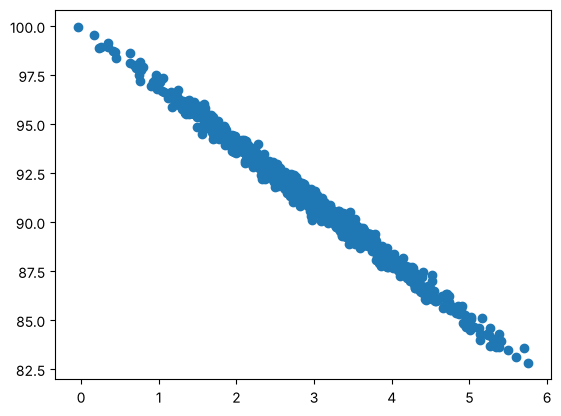

In [1]:
%matplotlib inline
import numpy as np
from pylab import *

np.random.seed(0)   # pour avoir les mêmes résultats à chaque exécution

pageSpeeds = np.random.normal(3.0, 1.0, 1000)
purchaseAmount = 100 - (pageSpeeds + np.random.normal(0, 0.1, 1000)) * 3

scatter(pageSpeeds, purchaseAmount)

As we only have two features, we can keep it simple and just use scipy.state.linregress:

In [2]:
from scipy import stats

slope, intercept, r_value, p_value , std_err = stats.linregress(pageSpeeds, purchaseAmount)


The R-squared value shows the following fit:

In [3]:
r_value ** 2

np.float64(0.9904212693592981)

Let's use the slope and intercept we got from the regression to plot predicted values vs. observed:

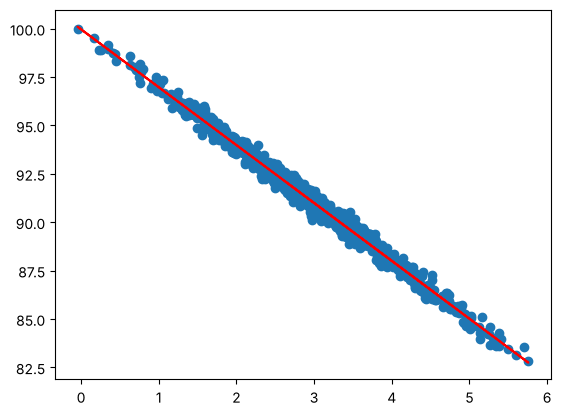

In [4]:
import matplotlib.pyplot as plt

def predict(x):
    return slope * x + intercept

fitLine = predict(pageSpeeds)

plt.scatter(pageSpeeds, purchaseAmount)
plt.plot(pageSpeeds, fitLine, c='r')
plt.show()

The function `stats.linregress` from **SciPy** is mainly designed to compute:

- **slope**  
- **intercept**  
- **r-value** (correlation coefficient)  
- **p-value**  
- **standard error of the slope**

It does **not** directly compute **RMSE** — but you can easily calculate it yourself using the predictions it gives you.

In [5]:
# Predicted values
y_pred = intercept + slope * pageSpeeds

# RMSE
rmse = np.sqrt(np.mean((purchaseAmount - y_pred)**2))

print("RMSE:", rmse)
print("R²:", r_value**2)

RMSE: 0.2903037851170611
R²: 0.9904212693592981


## Activity

- Using the predicted and actual values from your linear regression model, compute the following evaluation metrics:
   - **MAE** (Mean Absolute Error)  
   - **MSE** (Mean Squared Error)    
   - **RSS** (Residual Sum of Squares)  
   - **RAE** (Relative Absolute Error). Organize your results in a clear format (table or print statements) including the obtained **R²** and **RMSE** 

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_true = purchaseAmount
y_pred = predict(pageSpeeds)

mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
rss = np.sum((y_true - y_pred) ** 2)
# RAE = somme des erreurs absolues / somme des écarts absolus à la moyenne
rae = np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true - np.mean(y_true)))
r2 = r2_score(y_true, y_pred)

import pandas as pd
resultats = pd.DataFrame({'Métrique': ['MAE', 'MSE', 'RMSE', 'RSS', 'RAE', 'R²'],
                          'Valeur': [mae, mse, rmse, rss, rae, r2]})
print(resultats.to_string(index=False))

Métrique    Valeur
     MAE  0.231067
     MSE  0.084276
    RMSE  0.290304
     RSS 84.276288
     RAE  0.098048
      R²  0.990421


   - Which metric(s) give a sense of how far predictions are from actual values?  
   - Which metric allows for comparison across different scales?  
   - Based on these metrics, how well does your model fit the data?

**Réponses :**

- Les métriques qui donnent une idée de la distance entre les prédictions et les vraies valeurs sont **MAE** et **RMSE**, car elles sont exprimées dans la même unité que la variable cible (ici environ 0.23 et 0.29 pour des montants autour de 91). Le MSE et le RSS sont en unité au carré donc plus difficiles à interpréter, mais ils servent à comparer des modèles entre eux.
- Pour comparer entre des échelles différentes il faut des métriques sans unité : **R²** (proportion de variance expliquée) et **RAE** (erreur relative par rapport à un modèle qui prédit toujours la moyenne).
- Le modèle s'ajuste très bien aux données : R² = 0.99, donc 99% de la variance est expliquée, et RAE = 0.098, donc l'erreur est environ 10 fois plus petite que celle du modèle "moyenne". Le RMSE (0.29) est proche du bruit qu'on a ajouté à la main (0.1 * 3 = 0.3), donc on ne peut pas faire beaucoup mieux.

- Try increasing the random variation in the test data, and see what effect it has on the r-squared error value.

In [7]:
# on augmente le bruit ajouté dans les données et on regarde le R²
np.random.seed(0)
for bruit in [0.1, 1, 3, 5, 10, 20]:
    pageSpeeds2 = np.random.normal(3.0, 1.0, 1000)
    purchaseAmount2 = 100 - (pageSpeeds2 + np.random.normal(0, bruit, 1000)) * 3
    slope2, intercept2, r_value2, p_value2, std_err2 = stats.linregress(pageSpeeds2, purchaseAmount2)
    print("bruit =", bruit, "-> R² =", round(r_value2 ** 2, 4))

bruit = 0.1 -> R² = 0.9904
bruit = 1 -> R² = 0.4745
bruit = 3 -> R² = 0.0831
bruit = 5 -> R² = 0.0499
bruit = 10 -> R² = 0.011
bruit = 20 -> R² = 0.0039


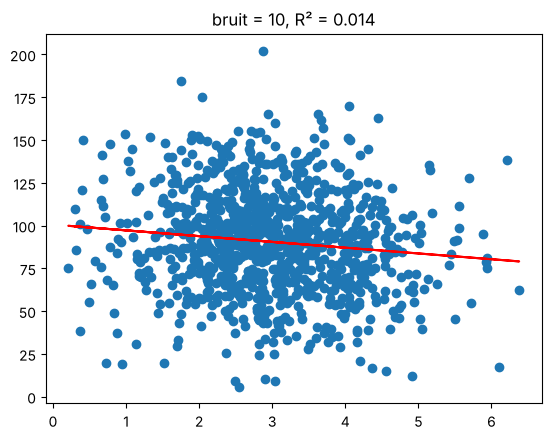

In [8]:
# visualisation avec un bruit élevé
pageSpeeds2 = np.random.normal(3.0, 1.0, 1000)
purchaseAmount2 = 100 - (pageSpeeds2 + np.random.normal(0, 10, 1000)) * 3
slope2, intercept2, r_value2, p_value2, std_err2 = stats.linregress(pageSpeeds2, purchaseAmount2)

plt.scatter(pageSpeeds2, purchaseAmount2)
plt.plot(pageSpeeds2, slope2 * pageSpeeds2 + intercept2, c='r')
plt.title("bruit = 10, R² = " + str(round(r_value2 ** 2, 3)))
plt.show()

Quand on augmente le bruit, le R² diminue très vite : 0.99 pour 0.1, environ 0.47 pour 1, 0.08 pour 3 et presque 0 pour 10 et 20. La droite de régression garde à peu près la même pente mais les points sont de plus en plus dispersés autour, donc le modèle explique de moins en moins la variance des données.